### Proyecto de grado MIAD

Presentado por:
- Laura Marcela Ramirez Casallas
- Kevin Alejandro Caicedo Rodriguez
- Jhon Jairo Meneses Prieto
- Jeferson Andrés Gutiérrez Gutiérrez

## 1. Importación de librerías y datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
from itertools import combinations
import numpy as np

In [ ]:
df = pd.read_excel("ProyecciónPoblaciónMunicipio.xlsx",sheet_name="PobMunicipalxÁrea")

df.head(15)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,PROYECCIONES DE POBLACIÓN Y ESTUDIOS DEMOGRÁFI...,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MUNICIPAL. PROYECCIONES DE POBLACIÓN POR ÁREA ...,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,PROYECCIONES DE POBLACIÓN POR ÁREA. AÑOS 2018 ...,NaN,NaN,NaN,NaN,NaN,NaN
6,DP,DPNOM,MPIO,DPMP,AÑO,ÁREA GEOGRÁFICA,TOTAL
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,05,Antioquia,05001,Medellín,2018,Cabecera Municipal,2382405
9,05,Antioquia,05001,Medellín,2018,Centros Poblados y Rural Disperso,44728


In [3]:
df = df.iloc[6:].reset_index(drop=True)

In [4]:
df.head(15)

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,DP,DPNOM,MPIO,DPMP,AÑO,ÁREA GEOGRÁFICA,TOTAL
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,05,Antioquia,05001,Medellín,2018,Cabecera Municipal,2382405
3,05,Antioquia,05001,Medellín,2018,Centros Poblados y Rural Disperso,44728
4,05,Antioquia,05001,Medellín,2018,Total,2427133
5,05,Antioquia,05002,Abejorral,2018,Cabecera Municipal,7669
6,05,Antioquia,05002,Abejorral,2018,Centros Poblados y Rural Disperso,12699
7,05,Antioquia,05002,Abejorral,2018,Total,20368
8,05,Antioquia,05004,Abriaquí,2018,Cabecera Municipal,834
9,05,Antioquia,05004,Abriaquí,2018,Centros Poblados y Rural Disperso,1884


In [5]:
# Promover la primera fila a encabezados
df.columns = df.iloc[0]

# Eliminar la fila que ahora es el encabezado
df = df.iloc[1:].reset_index(drop=True)

#Eliminar fila de espacio adicional
df = df.iloc[1:].reset_index(drop=True)

In [6]:
df.head(15)

,DP,DPNOM,MPIO,DPMP,AÑO,ÁREA GEOGRÁFICA,TOTAL
0,05,Antioquia,05001,Medellín,2018,Cabecera Municipal,2382405
1,05,Antioquia,05001,Medellín,2018,Centros Poblados y Rural Disperso,44728
2,05,Antioquia,05001,Medellín,2018,Total,2427133
3,05,Antioquia,05002,Abejorral,2018,Cabecera Municipal,7669
4,05,Antioquia,05002,Abejorral,2018,Centros Poblados y Rural Disperso,12699
5,05,Antioquia,05002,Abejorral,2018,Total,20368
6,05,Antioquia,05004,Abriaquí,2018,Cabecera Municipal,834
7,05,Antioquia,05004,Abriaquí,2018,Centros Poblados y Rural Disperso,1884
8,05,Antioquia,05004,Abriaquí,2018,Total,2718
9,05,Antioquia,05021,Alejandría,2018,Cabecera Municipal,2480


In [8]:
df.tail(15)

,DP,DPNOM,MPIO,DPMP,AÑO,ÁREA GEOGRÁFICA,TOTAL
84218,99,Vichada,99524,La Primavera,2042,Total,10527
84219,99,Vichada,99624,Santa Rosalía,2042,Cabecera Municipal,2190
84220,99,Vichada,99624,Santa Rosalía,2042,Centros Poblados y Rural Disperso,1526
84221,99,Vichada,99624,Santa Rosalía,2042,Total,3716
84222,99,Vichada,99773,Cumaribo,2042,Cabecera Municipal,4461
84223,99,Vichada,99773,Cumaribo,2042,Centros Poblados y Rural Disperso,176148
84224,99,Vichada,99773,Cumaribo,2042,Total,180609
84225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
84226,NaN,NaN,NaN,NaN,NaN,NaN,NaN
84227,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
df = df.iloc[:-8].copy()

In [10]:
df.tail(15)

,DP,DPNOM,MPIO,DPMP,AÑO,ÁREA GEOGRÁFICA,TOTAL
84210,97,Vaupés,97889,Yavaraté (ANM),2042,Cabecera Municipal,0
84211,97,Vaupés,97889,Yavaraté (ANM),2042,Centros Poblados y Rural Disperso,1190
84212,97,Vaupés,97889,Yavaraté (ANM),2042,Total,1190
84213,99,Vichada,99001,Puerto Carreño,2042,Cabecera Municipal,21661
84214,99,Vichada,99001,Puerto Carreño,2042,Centros Poblados y Rural Disperso,7423
84215,99,Vichada,99001,Puerto Carreño,2042,Total,29084
84216,99,Vichada,99524,La Primavera,2042,Cabecera Municipal,6167
84217,99,Vichada,99524,La Primavera,2042,Centros Poblados y Rural Disperso,4360
84218,99,Vichada,99524,La Primavera,2042,Total,10527
84219,99,Vichada,99624,Santa Rosalía,2042,Cabecera Municipal,2190


## 2. Conocimiento inicial de la base

In [11]:
# Número de filas y columnas
print("Filas y columnas:", df.shape)

Filas y columnas: (84225, 7)


In [12]:
# Código del departamento
df["DP"] = df["DP"].astype("string").str.zfill(2)

# Nombre del departamento
df["DPNOM"] = df["DPNOM"].astype("string")

# Código del municipio
df["MPIO"] = df["MPIO"].astype("string").str.zfill(5)

# Nombre del municipio
df["DPMP"] = df["DPMP"].astype("string")


# INFORMACIÓN TEMPORAL

# Año de referencia
df["AÑO"] = pd.to_numeric(df["AÑO"], errors="raise").astype("Int64")


# CLASIFICACIÓN GEOGRÁFICA

# Área geográfica
df["ÁREA GEOGRÁFICA"] = (df["ÁREA GEOGRÁFICA"].astype("category"))

# POBLACIÓN

# Total de personas
df["TOTAL"] = pd.to_numeric(df["TOTAL"], errors="raise").astype("Int64")

# VERIFICAR RESULTADO

print(df.dtypes)

display(df.head())


0
DP                 string[python]
DPNOM              string[python]
MPIO               string[python]
DPMP               string[python]
AÑO                         Int64
ÁREA GEOGRÁFICA          category
TOTAL                       Int64
dtype: object


,DP,DPNOM,MPIO,DPMP,AÑO,ÁREA GEOGRÁFICA,TOTAL
0,05,Antioquia,05001,Medellín,2018,Cabecera Municipal,2382405
1,05,Antioquia,05001,Medellín,2018,Centros Poblados y Rural Disperso,44728
2,05,Antioquia,05001,Medellín,2018,Total,2427133
3,05,Antioquia,05002,Abejorral,2018,Cabecera Municipal,7669
4,05,Antioquia,05002,Abejorral,2018,Centros Poblados y Rural Disperso,12699


In [13]:
# Tipos de datos y cantidad de registros no nulos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 84225 entries, 0 to 84224
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   DP               84225 non-null  string  
 1   DPNOM            84225 non-null  string  
 2   MPIO             84225 non-null  string  
 3   DPMP             84225 non-null  string  
 4   AÑO              84225 non-null  Int64   
 5   ÁREA GEOGRÁFICA  84225 non-null  category
 6   TOTAL            84225 non-null  Int64   
dtypes: Int64(2), category(1), string(4)
memory usage: 4.1 MB


In [14]:
# Verificar que no existan combinaciones repetidas
claves = ["DP", "DPNOM", "MPIO", "DPMP", "AÑO"]

print(
    "Duplicados:",
    df.duplicated(
        subset=claves + ["ÁREA GEOGRÁFICA"]
    ).sum()
)


Duplicados: 0


In [15]:
# Transformar las categorías en columnas
df_poblacion = df.pivot(
    index=["DP", "DPNOM", "MPIO", "DPMP", "AÑO"],
    columns="ÁREA GEOGRÁFICA",
    values="TOTAL"
).reset_index()

# Eliminar el nombre del encabezado de columnas
df_poblacion.columns.name = None

# Renombrar las columnas
df_poblacion = df_poblacion.rename(columns={
    "Cabecera Municipal": "POB_CABECERA",
    "Centros Poblados y Rural Disperso": "POB_RURAL",
    "Total": "POB_TOTAL"
})

# Visualizar resultado
display(df_poblacion.head())


,DP,DPNOM,MPIO,DPMP,AÑO,POB_CABECERA,POB_RURAL,POB_TOTAL
0,05,Antioquia,05001,Medellín,2018,2382405,44728,2427133
1,05,Antioquia,05001,Medellín,2019,2409046,46290,2455336
2,05,Antioquia,05001,Medellín,2020,2441882,48073,2489955
3,05,Antioquia,05001,Medellín,2021,2459249,48371,2507620
4,05,Antioquia,05001,Medellín,2022,2466239,48470,2514709


In [16]:
# Verificar consistencia de los totales
coincide = (
    df_poblacion["POB_CABECERA"] +
    df_poblacion["POB_RURAL"]
    == df_poblacion["POB_TOTAL"]
)

print("Registros consistentes:", coincide.sum())
print("Registros inconsistentes:", (coincide == False).sum())
print("Registros sin datos suficientes:", coincide.isna().sum())

Registros consistentes: 28075
Registros inconsistentes: 0
Registros sin datos suficientes: 0


## Granularidad

La granularidad es municipio–año.

Cada fila representa la población de un municipio específico en un año determinado, desagregada en población de cabecera municipal, centros poblados y rural disperso, y población total.

## 3. Evaluación de la calidad de los datos

### 3.1. Completitud

In [17]:
completitud = pd.DataFrame({
    "Valores nulos": df_poblacion.isna().sum(),
    "% Nulos": (df_poblacion.isna().sum() / len(df_poblacion) * 100).round(2),
    "% Completitud": (100 - df_poblacion.isna().sum() / len(df_poblacion) * 100).round(2)
})

# Mostrar únicamente columnas con al menos un valor nulo
completitud = completitud[completitud["Valores nulos"] > 0]

display(completitud.sort_values("% Completitud"))

,Valores nulos,% Nulos,% Completitud


### 3.2. Consistencia

In [18]:
# Registros exactamente iguales en todas las columnas
print("Registros duplicados:", df_poblacion.duplicated().sum())

Registros duplicados: 0


### 3.3. Claridad

In [19]:
claridad = pd.DataFrame({
    "Tipo de dato": df_poblacion.dtypes,
    "Valores únicos": df_poblacion.nunique()
})

claridad

,Tipo de dato,Valores únicos
DP,string[python],33
DPNOM,string[python],33
MPIO,string[python],1123
DPMP,string[python],1040
AÑO,Int64,25
POB_CABECERA,Int64,15886
POB_RURAL,Int64,15884
POB_TOTAL,Int64,20730


In [20]:
# Muestra de hasta 15 valores diferentes por columna
resumen_valores = pd.DataFrame({
    "Columna": df_poblacion.columns,
    "Tipo de dato": df_poblacion.dtypes.astype(str).values,
    "Valores únicos": [
        ", ".join(map(str, df_poblacion[col].dropna().unique()[:15]))
        for col in df_poblacion.columns
    ],
    "Total valores únicos": [
        df_poblacion[col].nunique()
        for col in df_poblacion.columns
    ]
})

pd.set_option("display.max_rows", None)

display(resumen_valores)

,Columna,Tipo de dato,Valores únicos,Total valores únicos
0,DP,string,"05, 08, 11, 13, 15, 17, 18, 19, 20, 23, 25, 27...",33
1,DPNOM,string,"Antioquia, Atlántico, Bogotá, D.C., Bolívar, B...",33
2,MPIO,string,"05001, 05002, 05004, 05021, 05030, 05031, 0503...",1123
3,DPMP,string,"Medellín, Abejorral, Abriaquí, Alejandría, Ama...",1040
4,AÑO,Int64,"2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025...",25
5,POB_CABECERA,Int64,"2382405, 2409046, 2441882, 2459249, 2466239, 2...",15886
6,POB_RURAL,Int64,"44728, 46290, 48073, 48371, 48470, 48522, 4861...",15884
7,POB_TOTAL,Int64,"2427133, 2455336, 2489955, 2507620, 2514709, 2...",20730


### 3.4. Formato

In [21]:
# Tipos de datos detectados al cargar la base
pd.set_option("display.max_rows", None)
display(df_poblacion.dtypes)

DP              string[python]
DPNOM           string[python]
MPIO            string[python]
DPMP            string[python]
AÑO                      Int64
POB_CABECERA             Int64
POB_RURAL                Int64
POB_TOTAL                Int64
dtype: object

## 4. Descripción estadística de variables numéricas

Resumen de media, desviación estándar, mínimos, máximos y cuartiles.

In [49]:
numericas = df_poblacion.select_dtypes(include="number").drop(columns="AÑO")

if numericas.shape[1] > 0:
    display(numericas.describe().style.format("{:,.0f}"))
else:
    print("Esta base no tiene columnas numéricas reconocidas por pandas.")

,POB_CABECERA,POB_RURAL,POB_TOTAL
count,"28,075","28,075","28,075"
mean,"36,411","11,500","47,911"
std,"264,265","15,910","267,509"
min,0,0,0
25%,"2,106","3,548","6,908"
50%,"5,261","6,895","13,979"
75%,"14,611","13,157","30,217"
max,"7,914,911","242,076","7,945,996"


## 5. Exploración gráfica de variables numéricas

Primero se revisan los histogramas; luego, los diagramas de caja. Ambos procedimientos aparecen en los talleres.

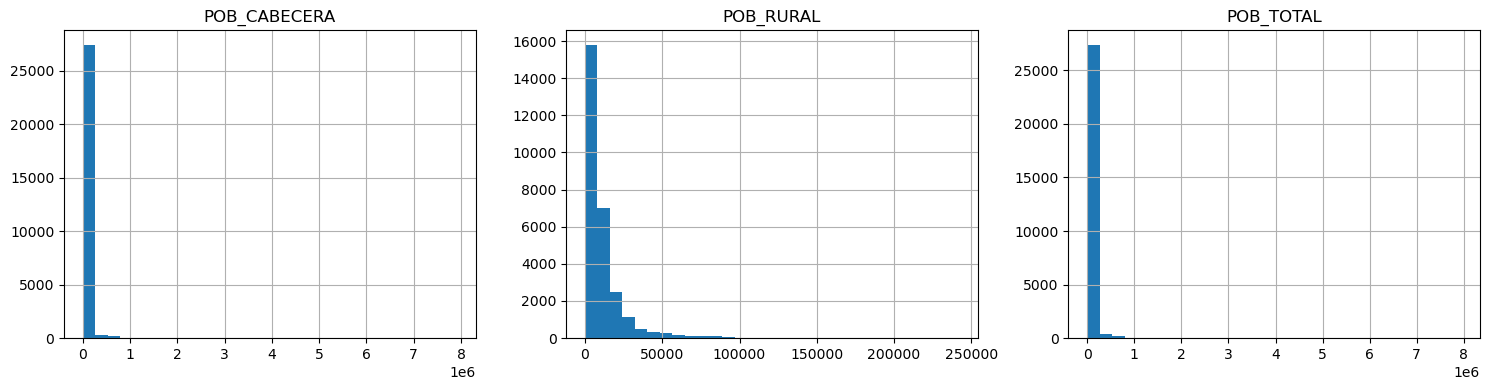

In [50]:
# Histogramas de las columnas numéricas
if numericas.shape[1] > 0:

    filas = math.ceil(numericas.shape[1] / 3)

    numericas.hist(figsize=(15, 4 * filas),bins=30,layout=(filas, 3)    )

    plt.tight_layout()
    plt.show()

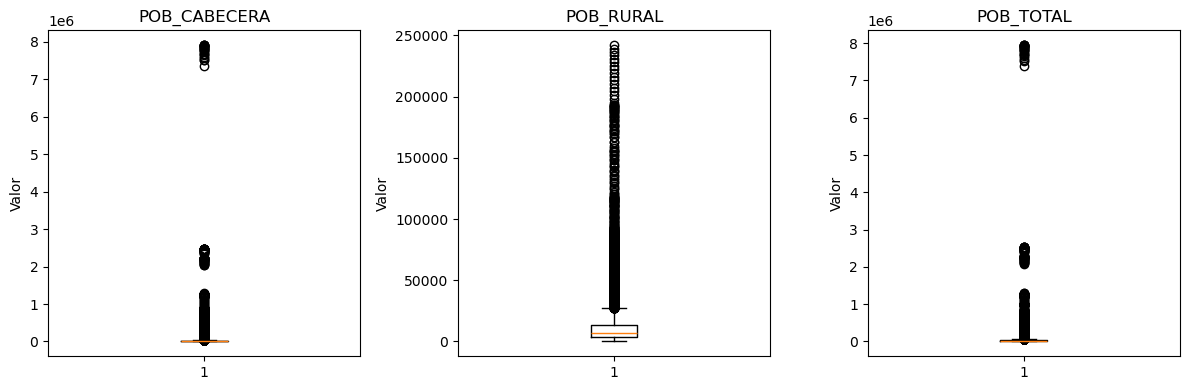

In [51]:
# Diagramas de caja por variable numérica
if numericas.shape[1] > 0:
    columnas = 3
    filas = math.ceil(numericas.shape[1] / columnas)

    plt.figure(figsize=(12, 4 * filas))

    for i, col in enumerate(numericas.columns):
        plt.subplot(filas, columnas, i + 1)
        plt.boxplot(numericas[col].dropna())
        plt.title(col)
        plt.ylabel("Valor")

    plt.tight_layout()
    plt.show()

**Para analizar:** ¿Cómo se distribuyen las variables? ¿Hay asimetrías, concentraciones o posibles valores atípicos? Un punto fuera del diagrama de caja no significa necesariamente un error.

## 6. Exploración de variables categóricas

Se identifican las frecuencias más frecuentes. Los gráficos muestran **hasta tres columnas categóricas** para que la salida no sea demasiado extensa; puedes cambiar `[:3]` según tu necesidad.

In [29]:
categoricas = df_poblacion.select_dtypes(include=["object", "category", "bool", "string"]).drop(columns=["DP","DPNOM","MPIO"])

In [30]:
categoricas.columns

Index(['DPMP'], dtype='object')

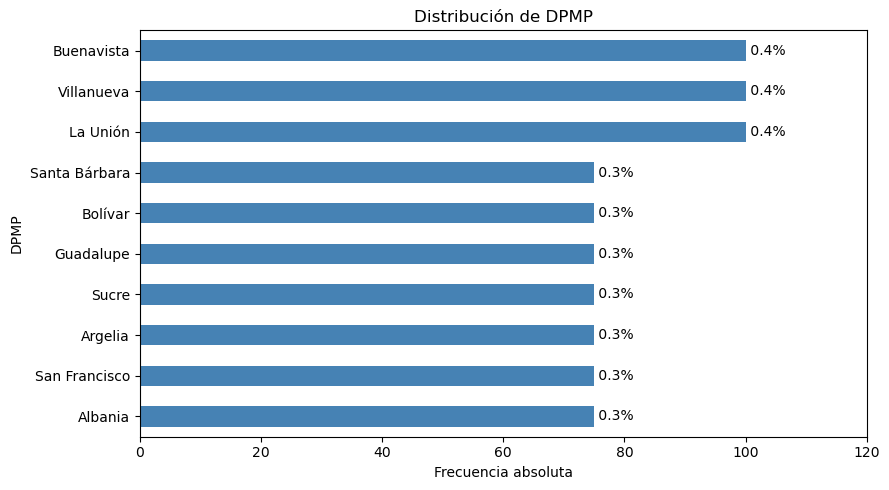

In [31]:
for col in categoricas.columns:

    frecuencias = df_poblacion[col].value_counts(
        dropna=False
    ).head(10).sort_values()

    ax = frecuencias.plot(
        kind="barh",
        figsize=(9, 5),
        color="steelblue"
    )

    # Agregar porcentajes al final de cada barra
    for i, valor in enumerate(frecuencias):
        porcentaje = (valor / len(df_poblacion)) * 100
        ax.text(valor, i, f" {porcentaje:.1f}%", va="center")

    plt.title(f"Distribución de {col}")
    plt.xlabel("Frecuencia absoluta")
    plt.ylabel(col)
    plt.xlim(0, frecuencias.max() * 1.20)
    plt.tight_layout()
    plt.show()

In [44]:
df_poblacion["DEPTO_MUNICIPIO"] = (
    df_poblacion["DPNOM"].astype(str).str.strip()
    + " - " +
    df_poblacion["DPMP"].astype(str).str.strip()
)

In [45]:
df_poblacion["DEPTO_MUNICIPIO"].nunique()

1123

In [46]:
df_poblacion["DEPTO_MUNICIPIO"].value_counts().head(10)

DEPTO_MUNICIPIO
Antioquia - Medellín    25
Nariño - La Llanada     25
Nariño - Magüí          25
Nariño - Los Andes      25
Nariño - Linares        25
Nariño - Leiva          25
Nariño - La Unión       25
Nariño - La Tola        25
Nariño - La Florida     25
Nariño - Mosquera       25
Name: count, dtype: int64

In [48]:
frecuencias = df_poblacion["DEPTO_MUNICIPIO"].value_counts()

frecuencias[frecuencias != 25]

Series([], Name: count, dtype: int64)

Despues de realizar el cruce nombre departamento-nombre municipio y contar los registros se confirma que cada uno de los 1123 departamentos tiene 25 registros correspondientes a los años de la proyección.

## 7. Relaciones entre variables numéricas

Matriz de correlación y mapa de calor. **Interpretar solo variables numéricas con significado cuantitativo:** no confundir códigos o identificadores con relaciones reales.

,POB_CABECERA,POB_RURAL,POB_TOTAL
POB_CABECERA,1.000000,0.175056,0.998284
POB_RURAL,0.175056,1.000000,0.232408
POB_TOTAL,0.998284,0.232408,1.000000


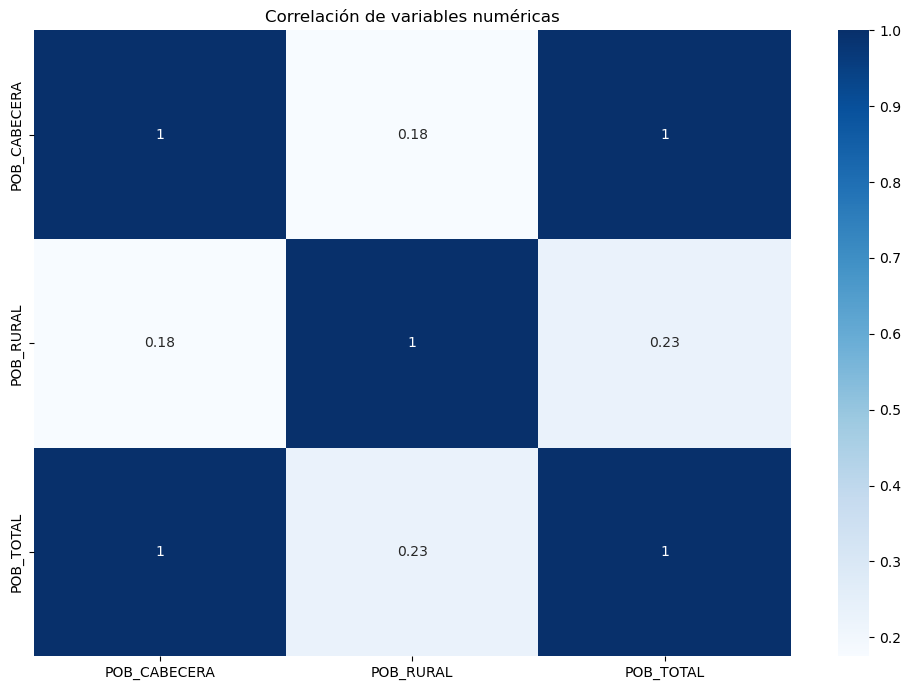

In [52]:
if numericas.shape[1] >= 2:
    correlaciones = numericas.corr()
    display(correlaciones)

    plt.figure(figsize=(10, 7))
    sns.heatmap(correlaciones, cmap="Blues", annot=True)
    plt.title("Correlación de variables numéricas")
    plt.tight_layout()
    plt.show()
else:
    print("No hay suficientes variables numéricas para calcular correlaciones.")

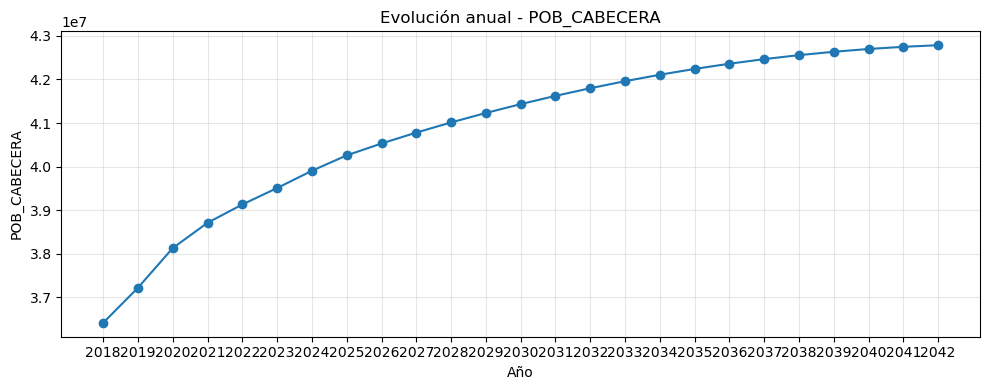

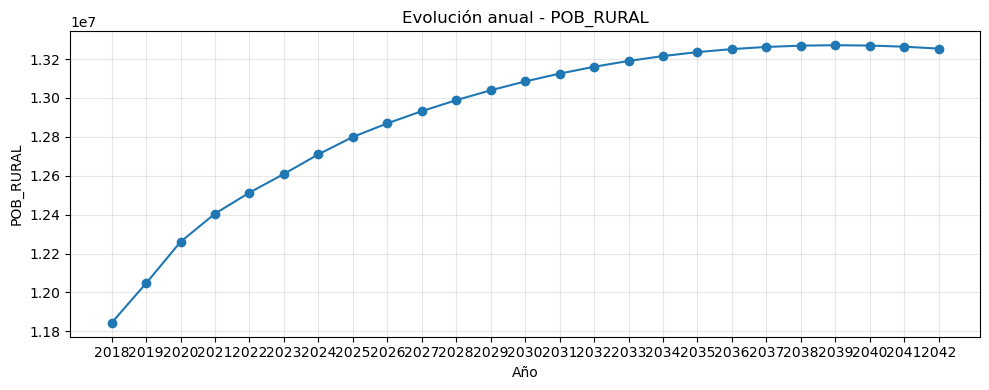

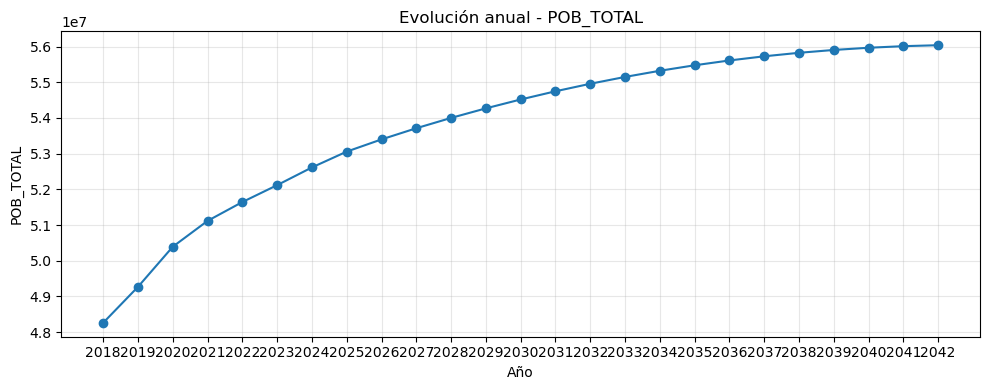

In [41]:
# Identificar las variables numéricas, excluyendo el año
numericas2 = df_poblacion.select_dtypes(include="number").columns.drop("AÑO", errors="ignore")

# Crear resumen anual
resumen_anual = df_poblacion.groupby("AÑO")[numericas2].sum().reset_index()

# Generar un gráfico independiente por variable
for col in numericas2:
    

    plt.figure(figsize=(10, 4))

    plt.plot(
        resumen_anual["AÑO"],
        resumen_anual[col],
        marker="o"
    )

    plt.title(f"Evolución anual - {col}")
    plt.xlabel("Año")
    plt.ylabel(col)
    plt.xticks(resumen_anual["AÑO"])
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


In [53]:
resumen_municipal = (df_poblacion.groupby(["AÑO", "DEPTO_MUNICIPIO"])["POB_TOTAL"].sum().reset_index())

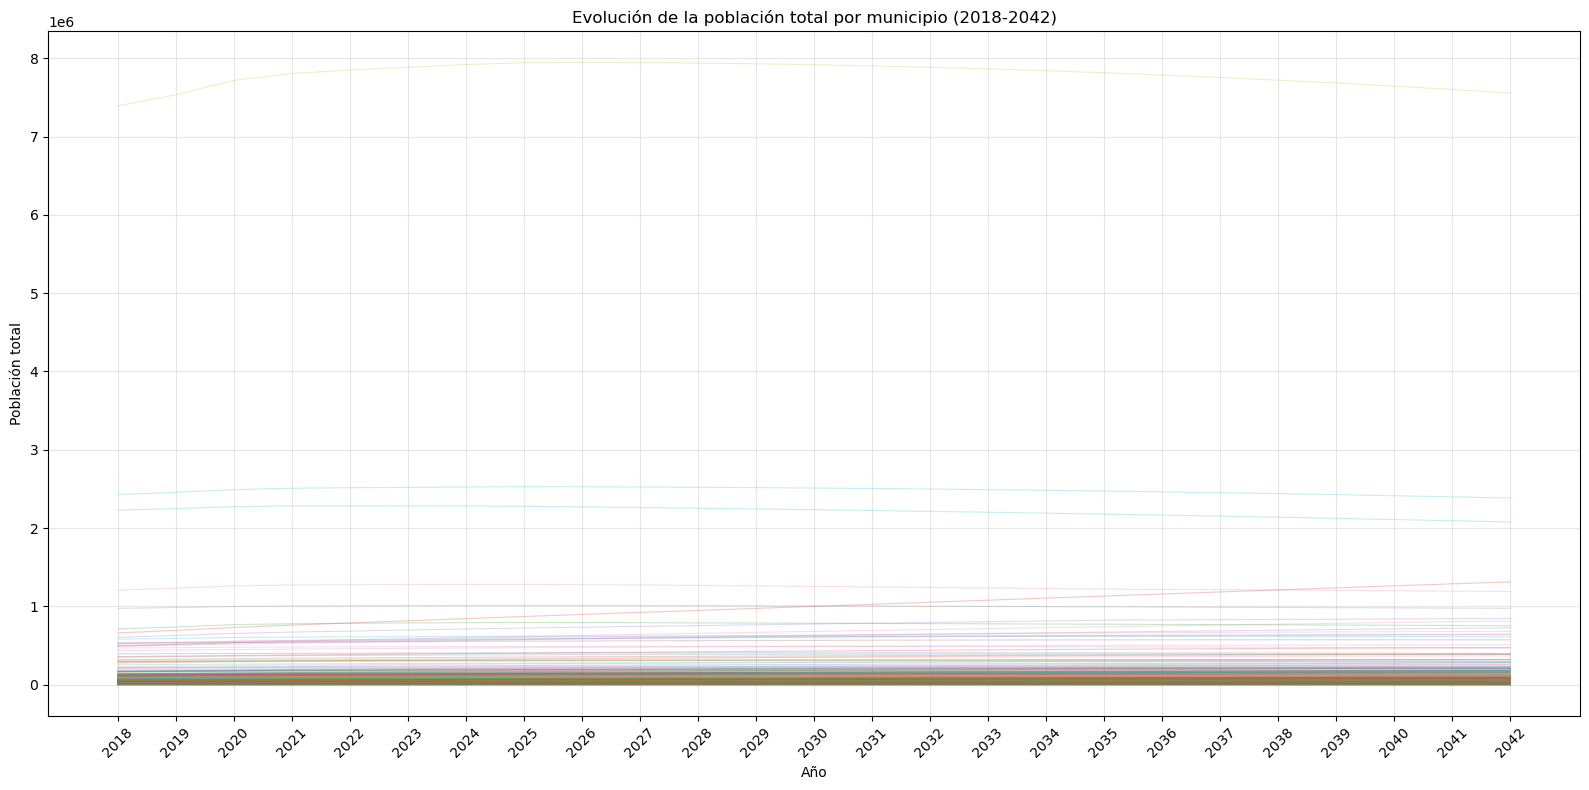

In [56]:
# Agrupar por año y municipio
resumen_municipal = (
    df_poblacion
    .groupby(["AÑO", "DEPTO_MUNICIPIO"])["POB_TOTAL"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(16, 8))

# Graficar todos los municipios
for municipio, grupo in resumen_municipal.groupby("DEPTO_MUNICIPIO"):

    plt.plot(
        grupo["AÑO"],
        grupo["POB_TOTAL"],
        alpha=0.25,
        linewidth=0.8
    )

plt.title("Evolución de la población total por municipio (2018-2042)")
plt.xlabel("Año")
plt.ylabel("Población total")
plt.xticks(sorted(resumen_municipal["AÑO"].unique()), rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

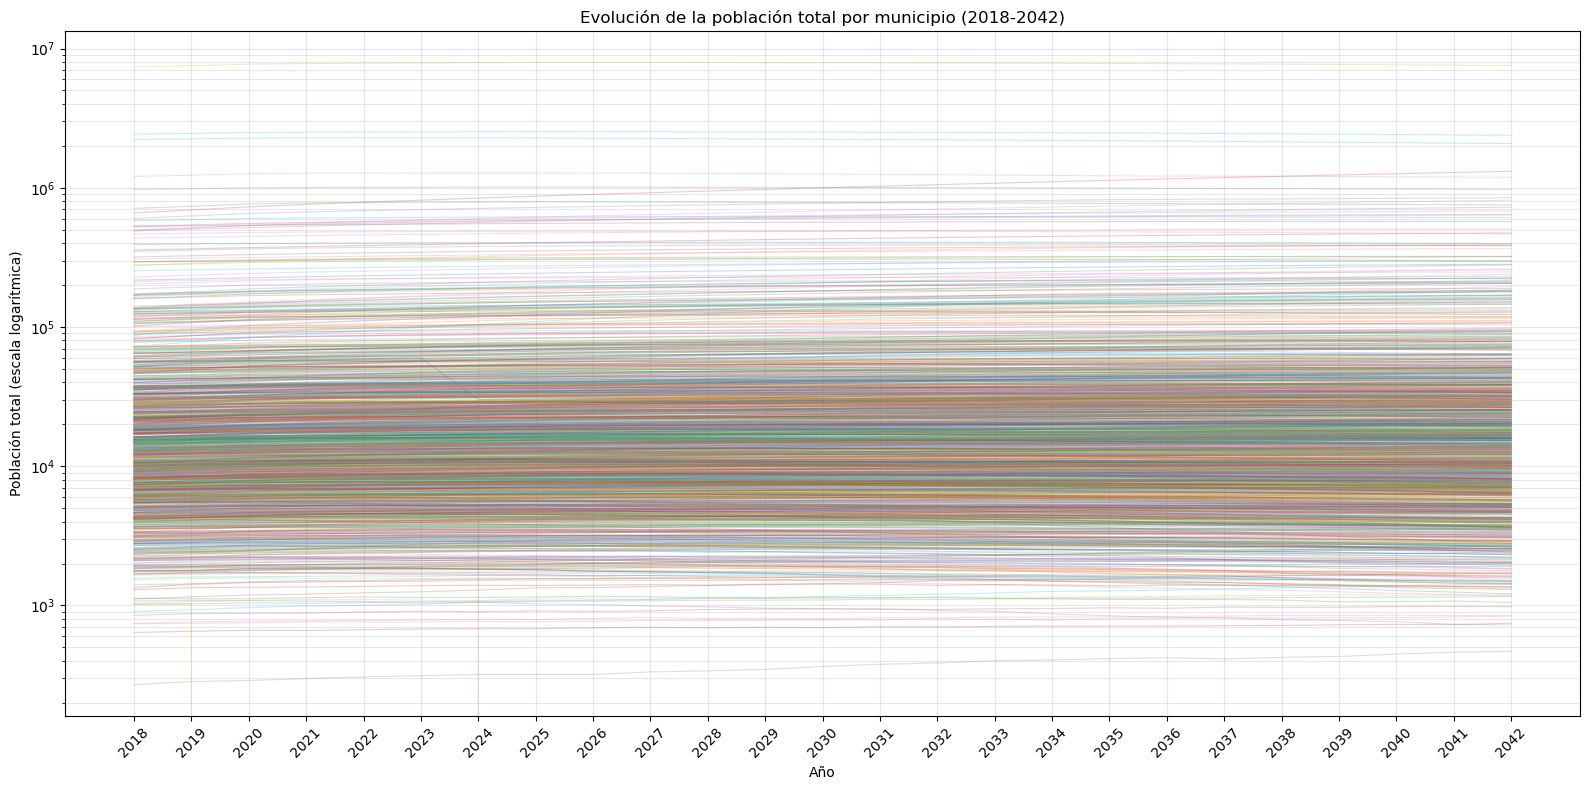

In [57]:
# Agrupar por año y municipio
resumen_municipal = (
    df_poblacion
    .groupby(["AÑO", "DEPTO_MUNICIPIO"])["POB_TOTAL"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(16, 8))

# Graficar todos los municipios
for municipio, grupo in resumen_municipal.groupby("DEPTO_MUNICIPIO"):

    plt.plot(
        grupo["AÑO"],
        grupo["POB_TOTAL"],
        alpha=0.25,
        linewidth=0.8
    )

# Aplicar escala logarítmica
plt.yscale("log")

plt.title("Evolución de la población total por municipio (2018-2042)")
plt.xlabel("Año")
plt.ylabel("Población total (escala logarítmica)")
plt.xticks(sorted(resumen_municipal["AÑO"].unique()), rotation=45)
plt.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.show()

In [58]:
# Obtener población inicial y final de cada municipio
crecimiento_municipal = (
    resumen_municipal[
        resumen_municipal["AÑO"].isin([2018, 2042])
    ]
    .pivot(
        index="DEPTO_MUNICIPIO",
        columns="AÑO",
        values="POB_TOTAL"
    )
    .reset_index()
)

# Calcular crecimiento porcentual
crecimiento_municipal["CRECIMIENTO_%"] = (
    (crecimiento_municipal[2042] - crecimiento_municipal[2018])
    / crecimiento_municipal[2018]
) * 100

# Ordenar de mayor a menor crecimiento
crecimiento_municipal = crecimiento_municipal.sort_values(
    "CRECIMIENTO_%",
    ascending=False
)

crecimiento_municipal.head(10)

AÑO,DEPTO_MUNICIPIO,2018,2042,CRECIMIENTO_%
486,Chocó - Nuevo Belén de Bajirá,0,32772,inf
1119,Vichada - Cumaribo,72563,180609,148.899577
526,Cundinamarca - Funza,93357,194980,108.854183
583,Cundinamarca - Soacha,659218,1312126,99.042805
556,Cundinamarca - Mosquera,130255,258239,98.256497
644,Guainía - Barrancominas,8076,15897,96.842496
509,Cundinamarca - Cajicá,87218,168664,93.3821
843,Norte de Santander - El Tarra,20079,38150,89.999502
518,Cundinamarca - Cota,34864,62577,79.488871
516,Cundinamarca - Chía,136742,239430,75.096167


d:\ProgramData\anaconda3\Lib\site-packages\matplotlib\transforms.py:2437: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


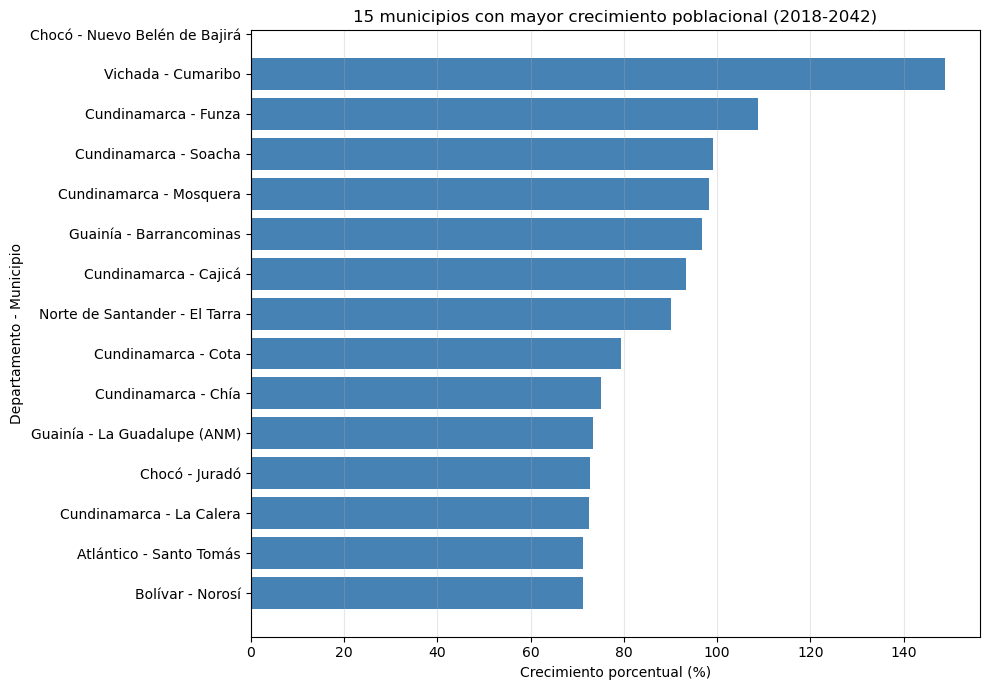

In [59]:
top_crecimiento = crecimiento_municipal.head(15).sort_values(
    "CRECIMIENTO_%"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_crecimiento["DEPTO_MUNICIPIO"],
    top_crecimiento["CRECIMIENTO_%"],
    color="steelblue"
)

plt.title("15 municipios con mayor crecimiento poblacional (2018-2042)")
plt.xlabel("Crecimiento porcentual (%)")
plt.ylabel("Departamento - Municipio")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

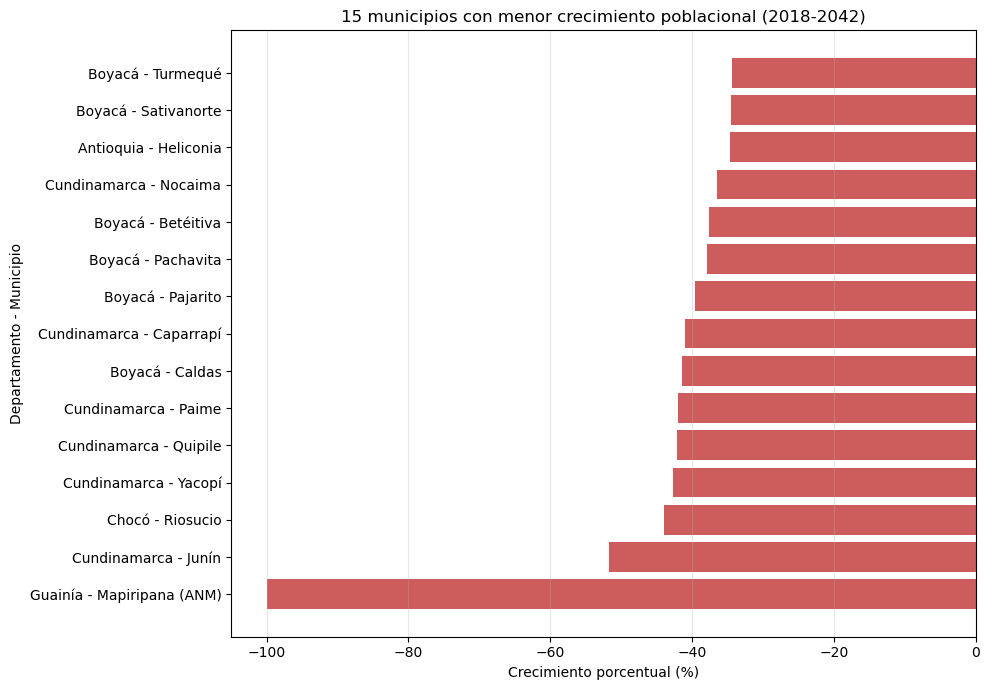

In [60]:
bottom_crecimiento = crecimiento_municipal.tail(15).sort_values(
    "CRECIMIENTO_%"
)

plt.figure(figsize=(10, 7))

plt.barh(
    bottom_crecimiento["DEPTO_MUNICIPIO"],
    bottom_crecimiento["CRECIMIENTO_%"],
    color="indianred"
)

plt.title("15 municipios con menor crecimiento poblacional (2018-2042)")
plt.xlabel("Crecimiento porcentual (%)")
plt.ylabel("Departamento - Municipio")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [61]:
municipios_revision = crecimiento_municipal[
    (crecimiento_municipal[2018] == 0) |
    (crecimiento_municipal[2018].isna())
]

municipios_revision[
    ["DEPTO_MUNICIPIO", 2018, 2042, "CRECIMIENTO_%"]
]

AÑO,DEPTO_MUNICIPIO,2018,2042,CRECIMIENTO_%
486,Chocó - Nuevo Belén de Bajirá,0,32772,inf


In [62]:
df_poblacion.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28075 entries, 0 to 28074
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   DP               28075 non-null  string
 1   DPNOM            28075 non-null  string
 2   MPIO             28075 non-null  string
 3   DPMP             28075 non-null  string
 4   AÑO              28075 non-null  Int64 
 5   POB_CABECERA     28075 non-null  Int64 
 6   POB_RURAL        28075 non-null  Int64 
 7   POB_TOTAL        28075 non-null  Int64 
 8   DEPTO_MUNICIPIO  28075 non-null  object
dtypes: Int64(4), object(1), string(4)
memory usage: 2.0+ MB
